# EEG Signal Analysis with Python

## Overview

This notebook explores a basic workflow for working with multichannel EEG data using Python. It uses **Pandas** and **NumPy** to load and organise the data, **Matplotlib** to visualise signals, and **SciPy** to demonstrate filtering and frequency-domain analysis.

The notebook covers:
- Loading and inspecting EEG data
- Extracting and visualising five EEG channels
- Understanding the time axis and sampling interval
- Demonstrating sampling and aliasing with a simulated signal
- Applying a Butterworth bandpass filter
- Estimating power spectral density (PSD) using Welch's method
- Calculating absolute and relative theta, alpha and beta band power
- Exploring the Fourier transform (FFT)

**Note:** This is a learning exercise using a sample dataset. The analysis and frequency-band values should not be interpreted as clinical findings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("sample_eeg_learning.csv")
print(df.head())

   time_s         C          O          F          P          T
0   0.000  0.609434   3.980770   5.562250  11.266190  12.922970
1   0.004  0.375307   5.926646   7.946276   7.220994  16.030443
2   0.008  6.276215   9.708396   9.160424  12.006612  12.187084
3   0.012  8.714089  10.505914  12.851019  13.854760  14.654754
4   0.016  4.614669  13.302743  13.260032  14.529661  16.176804


## 1. Loading the EEG Dataset and Required Libraries

The first step is to import the Python libraries used in the analysis and load the EEG dataset into a Pandas DataFrame.

The notebook expects a CSV file named `sample_eeg_learning.csv` in the same folder as this notebook. The following cells inspect the first few rows and the overall dimensions of the dataset.

In [2]:
print(df.shape)

(2500, 6)


## 2. Extracting EEG Channels and the Time Vector

The dataset contains five EEG channels (`C`, `O`, `F`, `P` and `T`) and a time column (`time_s`).

The selected channel columns are converted into a NumPy array and transposed so that each channel is represented as a separate row. The time values are extracted separately for plotting against the signal amplitudes.

In [3]:
data = df[["C", "O", "F", "P", "T"]].to_numpy().T
print(data.shape)

(5, 2500)


In [4]:
time = df["time_s"].to_numpy()
print(data.shape)
print(time.shape)

(5, 2500)
(2500,)


## 3. Visualising the EEG Signals

Visualising the raw signals is a useful first step when exploring EEG data.

The first plot displays channel C against time. The next plot displays all five channels, allowing their signal patterns to be viewed together.

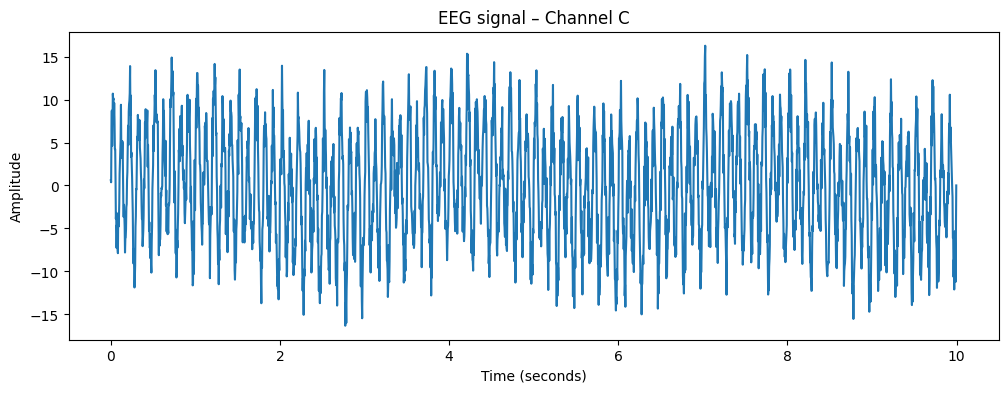

In [5]:
plt.figure(figsize=(12, 4))

plt.plot(time, data[0])

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("EEG signal – Channel C")

plt.show()

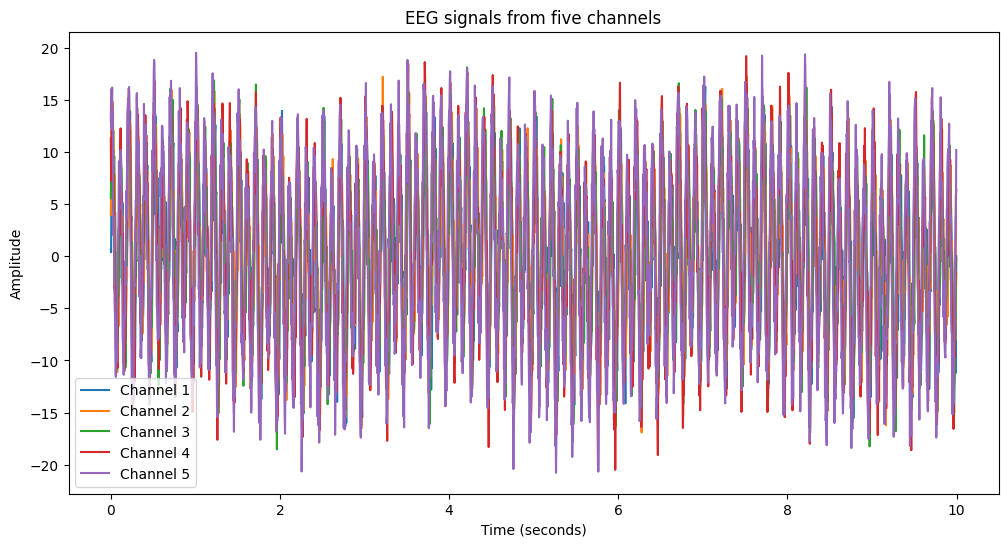

In [6]:
plt.figure(figsize=(12, 6))

for i in range(5):
    plt.plot(time, data[i], label=f"Channel {i+1}")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("EEG signals from five channels")
plt.legend()
plt.show()

## 4. Inspecting the Time Axis and Sampling Interval

Here, the notebook examines the number of time points, the first and last time values, and the difference between the first two time points.

The difference between consecutive time values gives the sampling interval. Its reciprocal corresponds to the sampling frequency when the samples are evenly spaced.

In [7]:
print(len(time))
print(time[0])
print(time[-1])
print(time[1] - time[0])

2500
0.0
9.996
0.004


## 5. Demonstrating Sampling and Aliasing

This section creates a simulated 40 Hz sine wave and samples it at two different sampling frequencies: 250 Hz and 50 Hz.

The plot compares the continuous-looking reference signal with the sampled points. It illustrates how a sampling rate that is too low can misrepresent the frequency of a signal. This is a demonstration using a simulated signal, not the recorded EEG dataset.

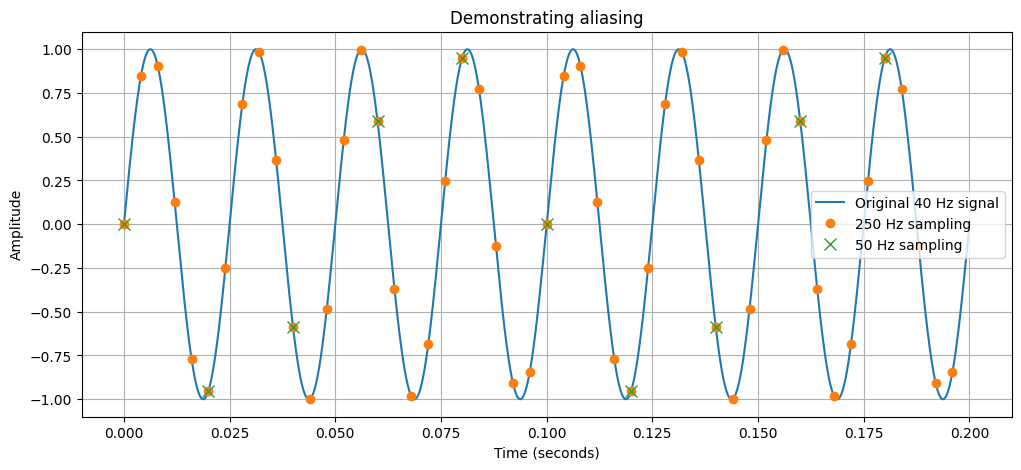

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a continuous-looking 40 Hz signal
t = np.linspace(0, 0.2, 2000)
original_signal = np.sin(2 * np.pi * 40 * t)

# Sample it at 250 Hz and 50 Hz
t_250 = np.arange(0, 0.2, 1/250)
t_50 = np.arange(0, 0.2, 1/50)

samples_250 = np.sin(2 * np.pi * 40 * t_250)
samples_50 = np.sin(2 * np.pi * 40 * t_50)

# Plot the comparison
plt.figure(figsize=(12, 5))

plt.plot(t, original_signal, label="Original 40 Hz signal")
plt.plot(t_250, samples_250, "o", label="250 Hz sampling")
plt.plot(t_50, samples_50, "x", markersize=9, label="50 Hz sampling")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Demonstrating aliasing")
plt.legend()
plt.grid()
plt.show()

## 6. Applying a Butterworth Bandpass Filter

A Butterworth bandpass filter is designed with cut-off frequencies of 8–12 Hz, corresponding to the alpha frequency range used in this notebook.

The filter is applied to the EEG data using `sosfiltfilt`, which performs forward and backward filtering. The resulting filtered signal is plotted alongside the original signal for channel C.

The sampling frequency supplied to the filter is **250 Hz**, as specified in the original code.

(5, 2500)


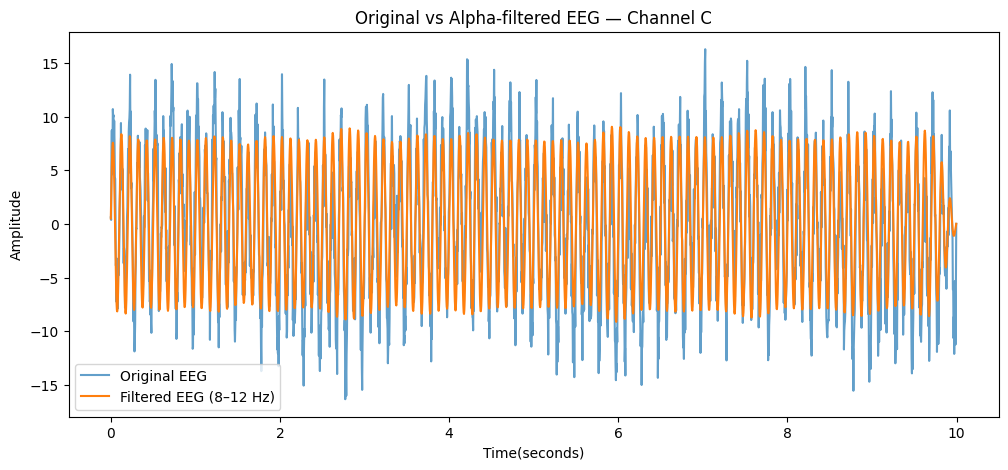

In [9]:
from scipy import signal

#Designing the filter (Butterworth)
sos = signal.butter(
    4,
    [8,12],
    btype='bandpass',
    fs=250,
    output='sos'
)

#Applying the filter
filtered_data  = signal.sosfiltfilt(sos, data, axis=1)
print(filtered_data.shape)

#Plotting the filtered signal in comparison with the orignal
plt.figure(figsize=(12,5))

plt.plot(time, data[0], label="Original EEG", alpha=0.7)
plt.plot(time, filtered_data[0], label="Filtered EEG (8–12 Hz)")

plt.xlabel("Time(seconds)")
plt.ylabel("Amplitude")
plt.title("Original vs Alpha-filtered EEG — Channel C")
plt.legend()
plt.show()

## 7. Estimating Power Spectral Density with Welch's Method

The power spectral density (PSD) describes how signal power is distributed across frequencies.

This section uses SciPy's `signal.welch()` function to estimate the PSD for channel C. The returned arrays contain the frequency values and their corresponding PSD estimates. The next cell plots this spectrum.

In [10]:

frequencies, psd = signal.welch(
    data[0],
    fs=250,
    nperseg=500
)
print(frequencies.shape)
print(psd.shape)


(251,)
(251,)


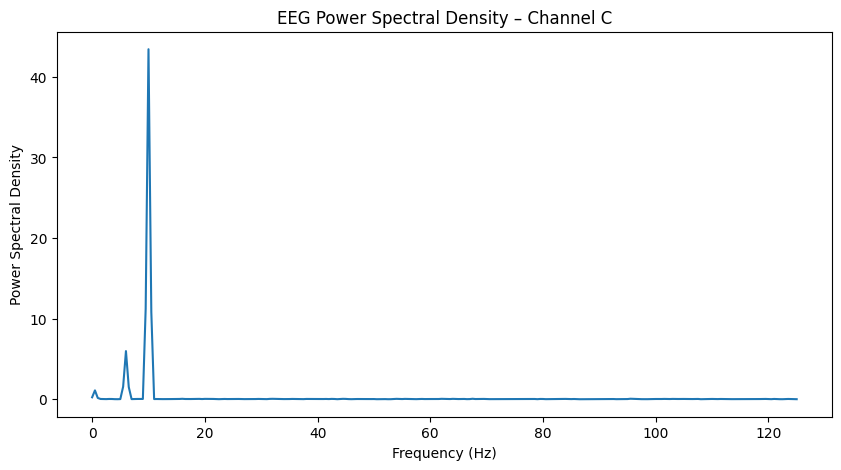

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(frequencies, psd)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.title("EEG Power Spectral Density – Channel C")

plt.show()

## 8. Calculating Absolute and Relative Alpha Power

The alpha range is defined here as 8–12 Hz.

The code selects PSD values within this frequency range and integrates them using the trapezoidal rule to estimate **absolute alpha power**. It then divides this value by the integrated total PSD to calculate **relative alpha power**, expressed as a percentage.

These calculations are performed for channel C in this section.

In [12]:
# TO CALCULATE ABSOLUTE ALPHA POWER

#Identify which frequency values fall between 8 and 12 Hz.
alpha_mask = (frequencies >= 8) & (frequencies <= 12)
print(frequencies[alpha_mask])

#Select the corresponding PSD values
alpha_psd = psd[alpha_mask]

#Calculate the area
from scipy.integrate import trapezoid
absolute_alpha_power = trapezoid(alpha_psd, frequencies[alpha_mask])
print("The absolute alpha power is:", absolute_alpha_power)

total_power = trapezoid(psd, frequencies)
relative_alpha_power = (absolute_alpha_power / total_power) * 100
print("The relative alpha power is:",relative_alpha_power)


[ 8.   8.5  9.   9.5 10.  10.5 11.  11.5 12. ]
The absolute alpha power is: 32.8431245592007
The relative alpha power is: 78.39052880672004


## 9. Estimating PSD Across All Five Channels

The same Welch PSD calculation is repeated for each of the five EEG channels.

The PSD arrays are stored in a dictionary (`all_psd`), with channel names used as keys. This makes it possible to calculate and compare frequency-band power across channels.

In [13]:
#Calculating PSD of all channels
channel_names = ["C", "O", "F", "P", "T"]

all_psd = {}

for i, channel in enumerate(channel_names):
    frequencies, psd = signal.welch(data[i], fs=250, nperseg=500)
    all_psd[channel] = psd
print(all_psd.keys())
print(all_psd["C"].shape)

dict_keys(['C', 'O', 'F', 'P', 'T'])
(251,)


## 10. Calculating Theta, Alpha and Beta Band Power

This section defines three frequency ranges:
- **Theta:** 4–8 Hz
- **Alpha:** 8–12 Hz
- **Beta:** 13–30 Hz

For each channel, the code selects the PSD values within each range and integrates them using the trapezoidal rule. The resulting absolute band-power estimates are stored in a dictionary and then organised into a Pandas DataFrame.

In [14]:
theta_mask = (frequencies >= 4) & (frequencies <= 8)

alpha_mask = (frequencies >= 8) & (frequencies <= 12)

beta_mask = (frequencies >= 13) & (frequencies <= 30)

from scipy.integrate import trapezoid

band_power = {}

for channel in channel_names:

    current_psd = all_psd[channel]

    theta = trapezoid(current_psd[theta_mask], frequencies[theta_mask])
    alpha = trapezoid(current_psd[alpha_mask], frequencies[alpha_mask])
    beta = trapezoid(current_psd[beta_mask], frequencies[beta_mask])

    band_power[channel] = {
        "Theta": theta,
        "Alpha": alpha,
        "Beta": beta
    }

print(band_power)

{'C': {'Theta': np.float64(4.592259040643128), 'Alpha': np.float64(32.8431245592007), 'Beta': np.float64(0.6101455565492788)}, 'O': {'Theta': np.float64(4.8840815834059494), 'Alpha': np.float64(40.605933216978066), 'Beta': np.float64(0.49317993097006585)}, 'F': {'Theta': np.float64(4.538291655591897), 'Alpha': np.float64(49.316626660624635), 'Beta': np.float64(0.5678615887330967)}, 'P': {'Theta': np.float64(4.608510545009528), 'Alpha': np.float64(61.20153126090892), 'Beta': np.float64(0.5530240574474417)}, 'T': {'Theta': np.float64(4.3626610936023), 'Alpha': np.float64(72.49716158431161), 'Beta': np.float64(0.5452493527398538)}}


In [15]:
band_df = pd.DataFrame.from_dict(band_power, orient="index")

print(band_df)

      Theta      Alpha      Beta
C  4.592259  32.843125  0.610146
O  4.884082  40.605933  0.493180
F  4.538292  49.316627  0.567862
P  4.608511  61.201531  0.553024
T  4.362661  72.497162  0.545249


## 11. Calculating Relative Band Power

Relative band power expresses the power in a frequency band as a percentage of the total PSD power.

For each channel, the notebook divides the absolute theta, alpha and beta power estimates by the total integrated PSD and multiplies by 100. The results are organised into a DataFrame for easier comparison across channels.

In [16]:
total_power = {}

for channel in channel_names:
    total = trapezoid(all_psd[channel], frequencies)
    total_power[channel] = total
    relative_power = {}

for channel in channel_names:
    relative_power[channel] = {
        "Theta": band_power[channel]["Theta"] / total_power[channel] * 100,
        "Alpha": band_power[channel]["Alpha"] / total_power[channel] * 100,
        "Beta": band_power[channel]["Beta"] / total_power[channel] * 100
    }
relative_df = pd.DataFrame.from_dict(relative_power, orient="index")

print(relative_df)

       Theta      Alpha      Beta
C  10.960882  78.390529  1.456306
O   9.794915  81.434281  0.989061
F   7.780892  84.553261  0.973598
P   6.551826  87.008982  0.786223
T   5.368323  89.208900  0.670938


In [17]:
relative_power = {}

for channel in channel_names:
    relative_power[channel] = {
        "Theta": band_power[channel]["Theta"] / total_power[channel] * 100,
        "Alpha": band_power[channel]["Alpha"] / total_power[channel] * 100,
        "Beta": band_power[channel]["Beta"] / total_power[channel] * 100
    }
relative_df = pd.DataFrame.from_dict(relative_power, orient="index")

print(relative_df)

       Theta      Alpha      Beta
C  10.960882  78.390529  1.456306
O   9.794915  81.434281  0.989061
F   7.780892  84.553261  0.973598
P   6.551826  87.008982  0.786223
T   5.368323  89.208900  0.670938


## 12. Exploring the Fourier Transform (FFT)

The final section introduces the Fast Fourier Transform (FFT), which converts a signal from the time domain into its frequency-domain representation.

The code calculates the FFT of channel C and then uses the absolute value of the complex FFT coefficients to obtain their magnitudes.

**This section is an initial exploration:** the current code prints the first few FFT coefficients and magnitudes. It does not yet map the coefficients to their corresponding frequency values or plot a frequency spectrum.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import fft

df=pd.read_csv("sample_eeg_learning.csv")

data = df[["C", "O", "F", "P", "T"]].to_numpy().T
time = df["time_s"].to_numpy()

print(data.shape)

fft_result = fft.fft(data[0])
print(fft_result.shape)
print(fft_result[:5])
magnitude = np.abs(fft_result)

print(magnitude[:5])

(5, 2500)
(2500,)
[-221.64112016   -0.j           29.78510604  -86.71922813j
  119.08905346  +66.71321093j  -77.35097151-2474.89411355j
 -106.84315988   +2.96224788j]
[ 221.64112016   91.69175028  136.50221671 2476.102592    106.88421645]
